<a href="https://colab.research.google.com/github/GitHubFers/mi-repositorio/blob/main/ACT_1Ejemplo_codigo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**

**Ciencia y analítica de datos**

MODELOS DE APRENDIZAJE


**ACTIVIDAD 1**

---

*   NOMBRE: Fernando Salazar Pérez
*   NO. CONTROL: 22111448

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


En esta actividad usarás el archivo de datos `Forbes_2000_top_company.csv`. Este conjunto contiene las 2000 principales empresas, clasificadas mediante el uso de cuatro métricas: ventas, ganancias, activos y valor de mercado. Tiene las 11 columnas de datos:

*   `2022 Ranking`: Ranking del año actual de la empresa
*   `Organization Name`: Nombre
*   `Industry`: El tipo de industria con la que trata principalmente
*   `Country`: País de origen
*   `Year Founded`: Año en que se fundó
*   `CEO`: CEO
*   `Profits (Billions)`: Ganancias del año
*   `Assets (Billions)`: Activos del año
*   `Market Value (Billions)`: Valor de mercado del año
*   `Total Employees`: Total de empleados

https://www.kaggle.com/datasets/ash316/forbes-top-2000-companies

Descarga el archivo: `Forbes_2000_top_company.csv` y guarda, en un dataframe (`forbes_df`), todos sus registros.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

forbes_df = pd.read_csv('/content/drive/MyDrive/Analítica de Datos/Unidad 2/practica 1/Forbes_2000_top_company.csv')
forbes_df.head()

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
0,1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
1,2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
2,3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
3,4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
4,5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621


In [ ]:
# Dimensionalidad del dataframe
forbes_df.shape

(1999, 11)

In [ ]:
# Identificadores de columnas
forbes_df.columns

Index(['2022 Ranking', 'Organization Name', 'Industry', 'Country',
       'Year Founded', 'CEO', 'Revenue (Billions)', 'Profits (Billions)',
       'Assets (Billions)', 'Market Value (Billions)', 'Total Employees'],
      dtype='object')

In [ ]:
# Identificadores de registros (filas)
forbes_df.index

RangeIndex(start=0, stop=1999, step=1)

In [ ]:
# Tipos de datos
forbes_df.dtypes

2022 Ranking                 int64
Organization Name           object
Industry                    object
Country                     object
Year Founded                 int64
CEO                         object
Revenue (Billions)         float64
Profits (Billions)         float64
Assets (Billions)          float64
Market Value (Billions)    float64
Total Employees              int64
dtype: object

---
**1. Gráfica de barras**

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Top 10 industrias con mas empresas (value_counts cuenta las filas por categoria)
top_ind = forbes_df['Industry'].value_counts().head(10)
sns.barplot(x=top_ind.values, y=top_ind.index, ax=axes[0], color='steelblue')
axes[0].set_title('Top 10 industrias por número de empresas')
axes[0].set_xlabel('Número de empresas')
axes[0].set_ylabel('')

# Top 10 paises
top_pais = forbes_df['Country'].value_counts().head(10)
sns.barplot(x=top_pais.values, y=top_pais.index, ax=axes[1], color='darkorange')
axes[1].set_title('Top 10 países por número de empresas')
axes[1].set_xlabel('Número de empresas')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

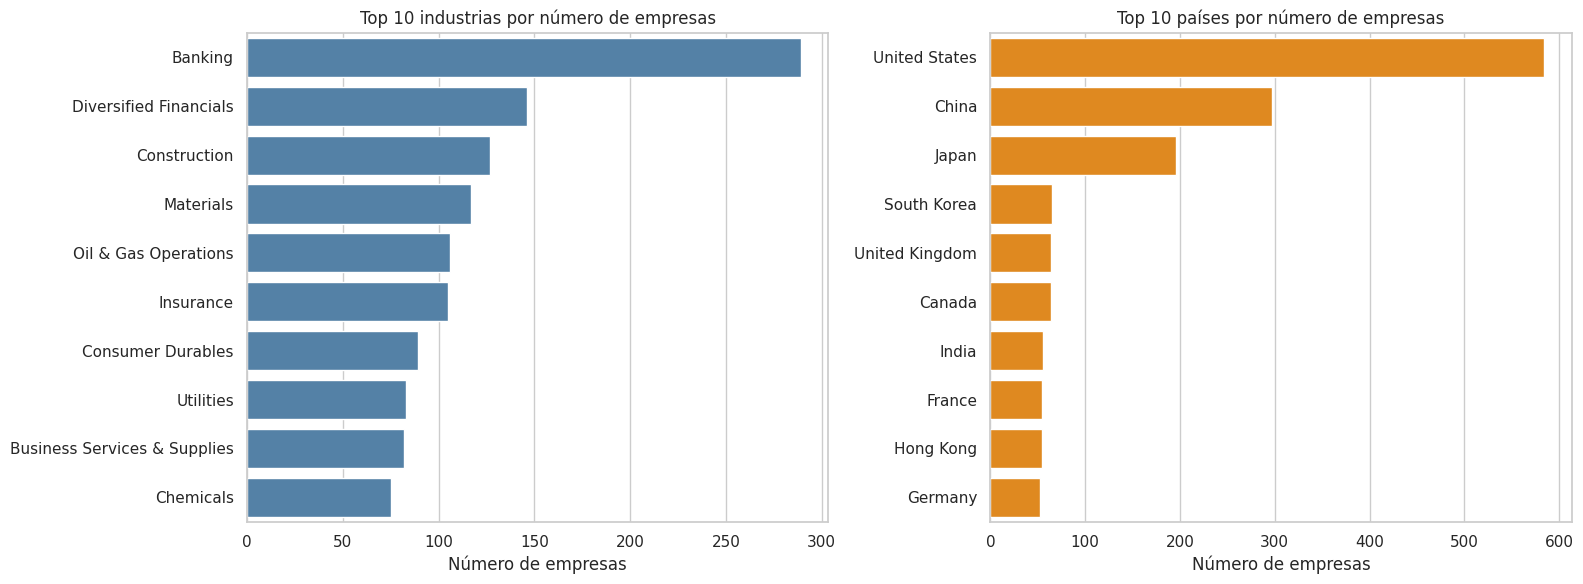

<font color="orange">**Justificación:** La industria con más empresas es *Banking* (289), seguida de *Diversified Financials* (146) y *Construction* (127): el sector financiero domina la lista. Por país, Estados Unidos lidera con 584 empresas (casi 30 % del total), seguido de China (297) y Japón (196); entre los tres suman más de la mitad de las 1,999 empresas.</font>

---
**2. Boxplots**

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
colores = sns.color_palette('Set2', len(num_cols))

for ax, col, color in zip(axes.flat, num_cols, colores):
    # boxplot: la caja muestra Q1-Q3, la linea central es la mediana y los puntos son valores atipicos
    sns.boxplot(y=forbes_df[col], ax=ax, color=color)
    ax.set_title(col)
    ax.set_ylabel('')

plt.suptitle('Boxplots de las variables numéricas', fontsize=16)
plt.tight_layout()
plt.show()

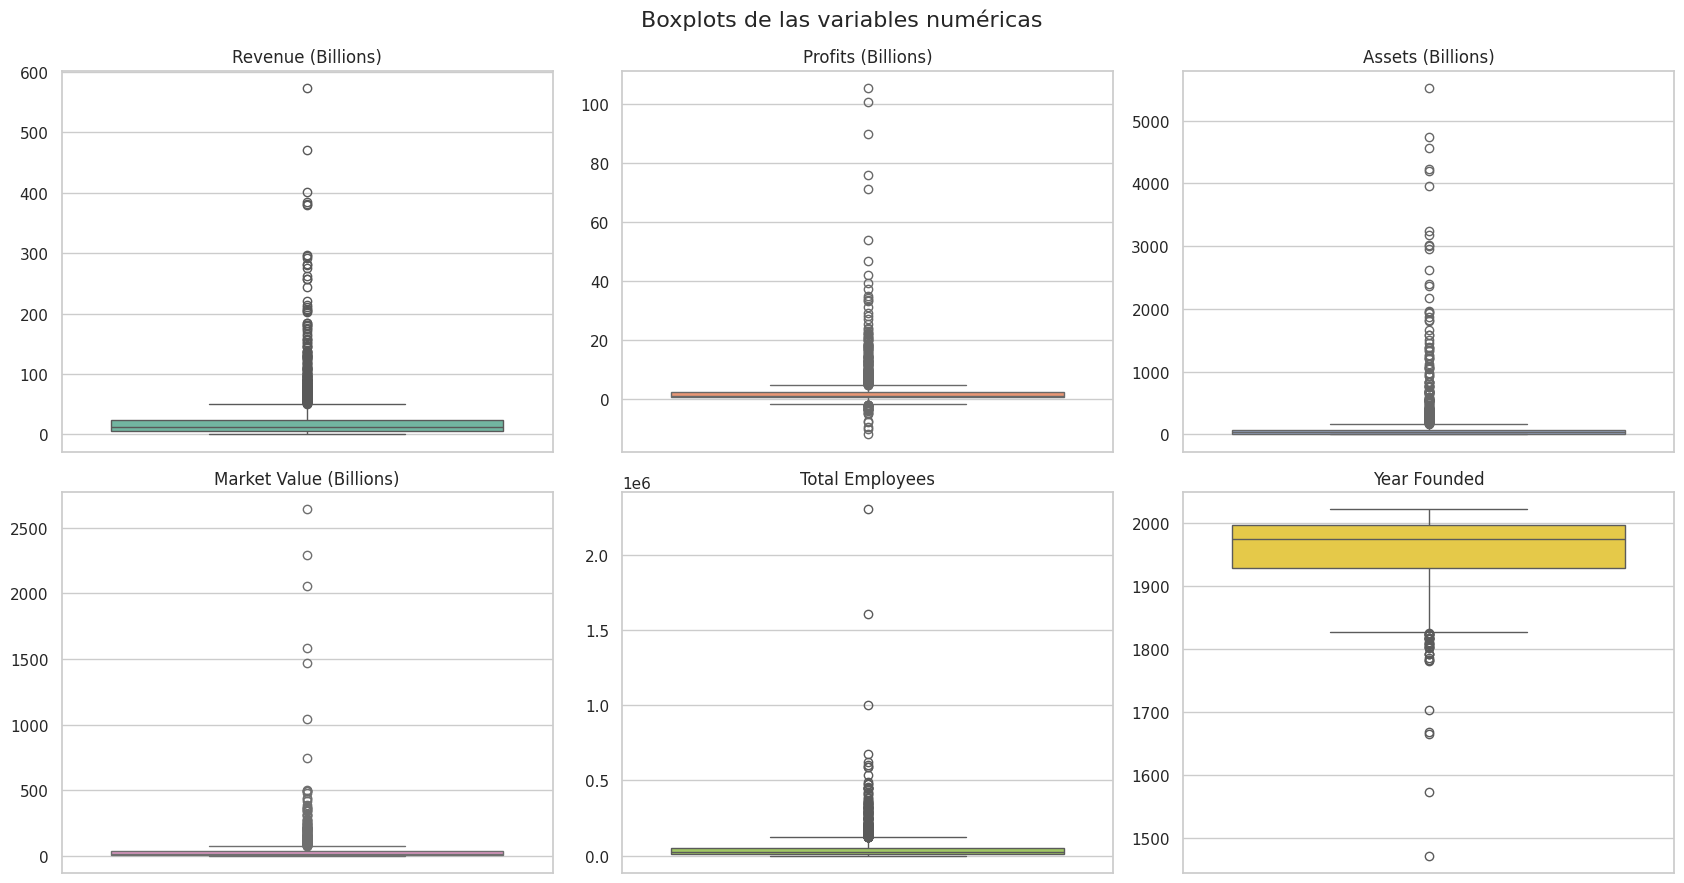

Como los valores atípicos aplastan las cajas en varias variables, se repite el boxplot con escala logarítmica en las variables positivas para ver mejor los cuartiles.

In [ ]:
# Escala logaritmica: ayuda a ver la caja cuando hay valores extremos muy grandes
log_cols = ['Revenue (Billions)', 'Assets (Billions)', 'Market Value (Billions)', 'Total Employees']
fig, axes = plt.subplots(1, 4, figsize=(17, 5))
for ax, col in zip(axes, log_cols):
    sns.boxplot(y=forbes_df[col], ax=ax, color='lightseagreen')
    ax.set_yscale('log')
    ax.set_title(col + ' (escala log)')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

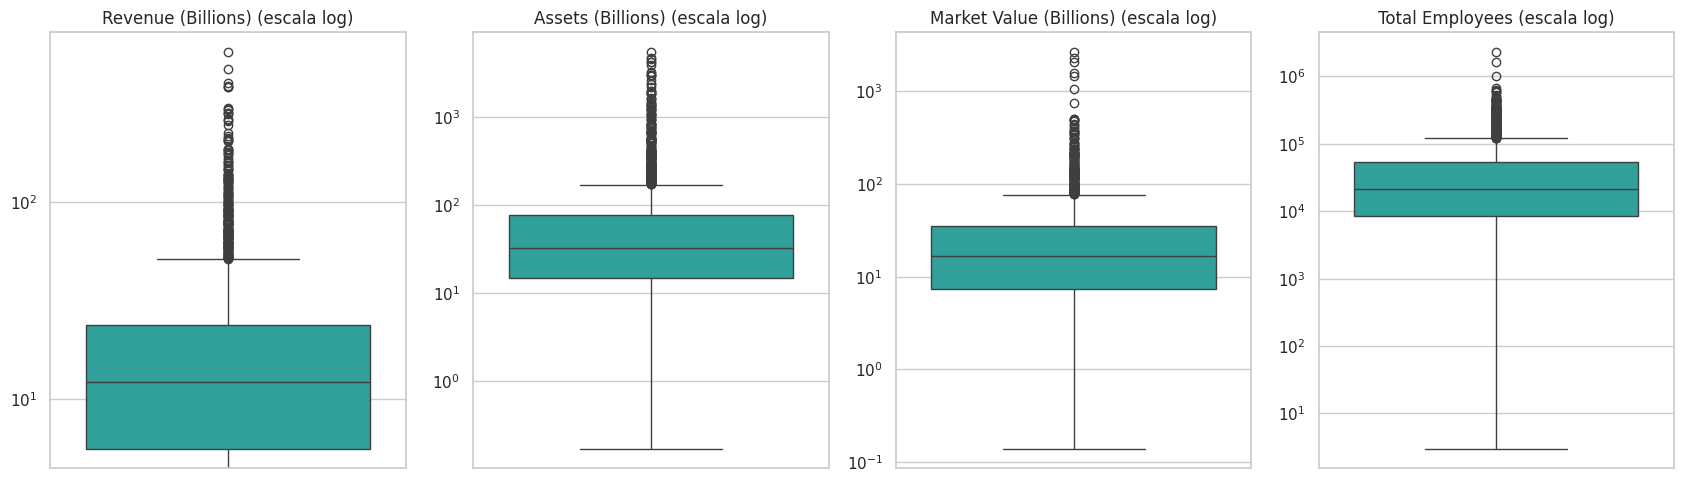

<font color="orange">**Justificación:** Todas las variables tienen muchos valores atípicos hacia arriba, lo que indica distribuciones muy sesgadas a la derecha: unas pocas empresas gigantes (Saudi Aramco, ICBC, Berkshire Hathaway...) están muy lejos del resto. La mediana de ingresos es ≈ 12.2 mil millones, la de ganancias ≈ 1.1, la de activos ≈ 32.1 y la de valor de mercado ≈ 16.6, mucho menores que sus máximos (572.8, 105.4, 5,518.5 y 2,640.3). En `Profits` hay 122 empresas con pérdidas (valores negativos). `Year Founded` es la más concentrada: la mediana es 1975 y los atípicos están hacia abajo (empresas muy antiguas). La escala logarítmica muestra que las cajas de `Assets` y `Market Value` son muy anchas: hay gran diferencia de tamaño entre empresas.</font>

---
**3. Diagramas de dispersión**

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

# 1) Ingresos vs ganancias (escala lineal)
sns.scatterplot(data=forbes_df, x='Revenue (Billions)', y='Profits (Billions)', alpha=0.5, ax=axes[0])
axes[0].axhline(0, color='red', linewidth=0.8, linestyle='--')   # linea de ganancia cero
axes[0].set_title('Ingresos vs. Ganancias')

# 2) Activos vs valor de mercado (ambos en escala log por los valores extremos)
sns.scatterplot(data=forbes_df, x='Assets (Billions)', y='Market Value (Billions)', alpha=0.5, color='darkorange', ax=axes[1])
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_title('Activos vs. Valor de mercado (escala log)')

# 3) Ingresos vs empleados (se omiten empresas sin dato de empleados o con ingresos 0 por la escala log)
datos = forbes_df[(forbes_df['Total Employees'] > 0) & (forbes_df['Revenue (Billions)'] > 0)]
sns.scatterplot(data=datos, x='Total Employees', y='Revenue (Billions)', alpha=0.5, color='seagreen', ax=axes[2])
axes[2].set_xscale('log'); axes[2].set_yscale('log')
axes[2].set_title('Empleados vs. Ingresos (escala log)')

plt.tight_layout()
plt.show()

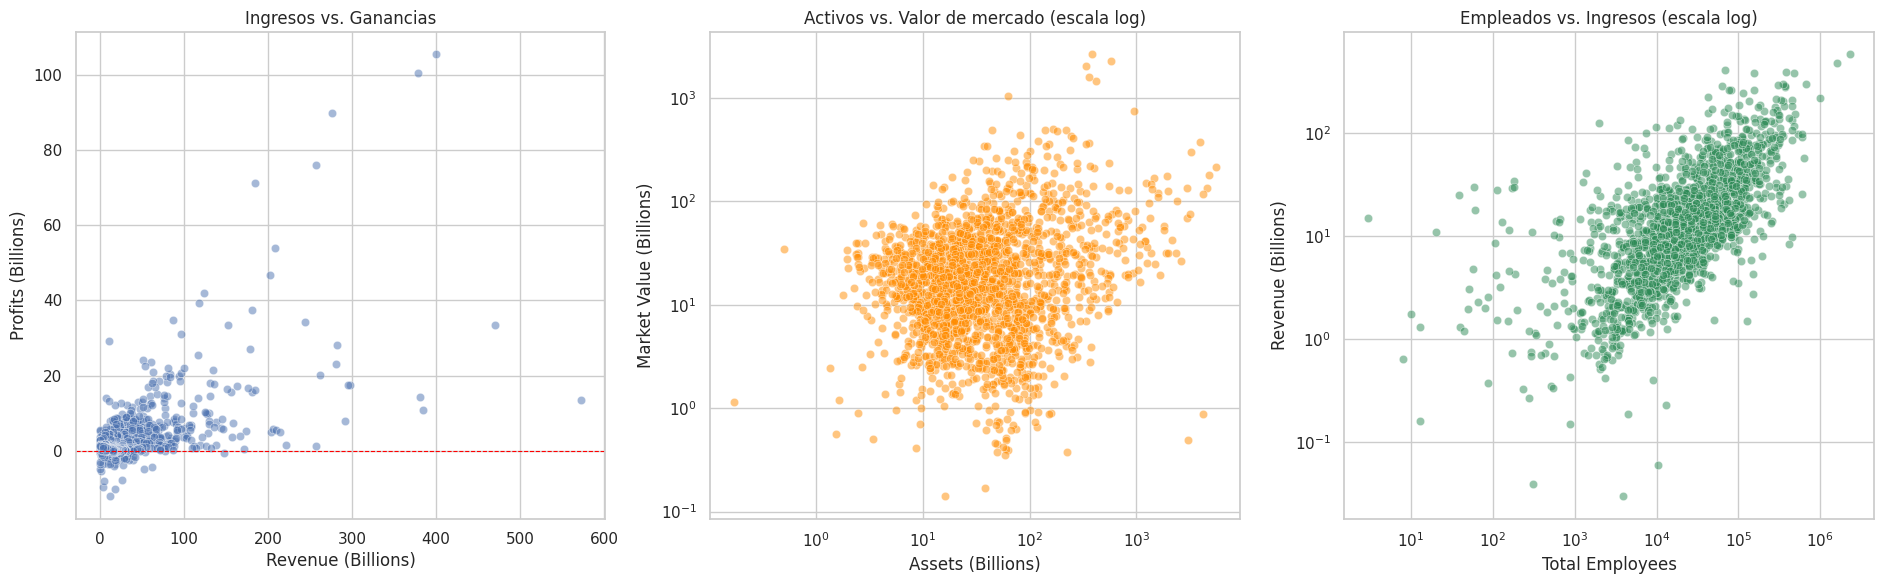

In [ ]:
# Coeficientes de correlacion de las parejas graficadas (Pearson)
print('Ingresos vs Ganancias:', round(forbes_df['Revenue (Billions)'].corr(forbes_df['Profits (Billions)']), 2))
print('Activos vs Valor de mercado:', round(forbes_df['Assets (Billions)'].corr(forbes_df['Market Value (Billions)']), 2))
print('Empleados vs Ingresos:', round(forbes_df['Total Employees'].corr(forbes_df['Revenue (Billions)']), 2))

Ingresos vs Ganancias: 0.64
Activos vs Valor de mercado: 0.15
Empleados vs Ingresos: 0.66

<font color="orange">**Justificación:** *Ingresos vs. Ganancias* (r ≈ 0.64): relación positiva moderada; las empresas con más ingresos tienden a ganar más, pero con mucha dispersión (algunas grandes empresas tienen pérdidas). *Activos vs. Valor de mercado* (r ≈ 0.15): relación débil; tener muchos activos no implica un alto valor de mercado. Esto es típico de bancos y aseguradoras, que tienen enormes activos pero valor de mercado moderado. *Empleados vs. Ingresos* (r ≈ 0.66): relación positiva moderada; más empleados suele asociarse con más ingresos, pero hay empresas con pocos empleados y muchos ingresos (por ejemplo, tecnológicas o financieras).</font>

---
**4. Mapa de calor**

In [ ]:
# Las columnas de tipo texto (object/str) se convierten a categorias y luego a su codigo numerico (0, 1, 2, ...)
cols_texto = codificado.select_dtypes(exclude='number').columns
for col in cols_texto:
    codificado[col] = codificado[col].astype('category').cat.codes

print('Columnas codificadas:', list(cols_texto))
codificado.head()

Columnas codificadas: ['Organization Name', 'Industry', 'Country', 'CEO']

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>2022 Ranking</th>
      <th>Organization Name</th>
      <th>Industry</th>
      <th>Country</th>
      <th>Year Founded</th>
      <th>CEO</th>
      <th>Revenue (Billions)</th>
      <th>Profits (Billions)</th>
      <th>Assets (Billions)</th>
      <th>Market Value (Billions)</th>
      <th>Total Employees</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>1</td>
      <td>284</td>
      <td>9</td>
      <td>54</td>
      <td>1939.0</td>
      <td>1787</td>
      <td>276.09</td>
      <td>89.80</td>
      <td>958.78</td>
      <td>741.48</td>
      <td>372000.0</td>
    </tr>
    <tr>
      <th>1</th>
      <td>2</td>
      <td>900</td>
      <td>2</td>
      <td>10</td>
      <td>1984.0</td>
      <td>1564</td>
      <td>208.13</td>
      <td>54.03</td>
      <td>5518.51</td>
      <td>214.42</td>
      <td>449296.0</td>
    </tr>
    <tr>
      <th>2</th>
      <td>3</td>
      <td>1547</td>
      <td>21</td>
      <td>42</td>
      <td>1933.0</td>
      <td>72</td>
      <td>400.38</td>
      <td>105.36</td>
      <td>576.04</td>
      <td>2292.08</td>
      <td>68493.0</td>
    </tr>
    <tr>
      <th>3</th>
      <td>4</td>
      <td>969</td>
      <td>9</td>
      <td>54</td>
      <td>2000.0</td>
      <td>748</td>
      <td>124.54</td>
      <td>42.12</td>
      <td>3954.69</td>
      <td>374.45</td>
      <td>271025.0</td>
    </tr>
    <tr>
      <th>4</th>
      <td>5</td>
      <td>409</td>
      <td>2</td>
      <td>10</td>
      <td>2014.0</td>
      <td>1786</td>
      <td>202.07</td>
      <td>46.89</td>
      <td>4746.95</td>
      <td>181.32</td>
      <td>352621.0</td>
    </tr>
  </tbody>
</table>
</div>

In [ ]:
# Matriz de correlacion con las 11 columnas
corr = codificado.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Mapa de calor - Correlación de todas las columnas (numéricas y de texto codificadas)')
plt.tight_layout()
plt.show()

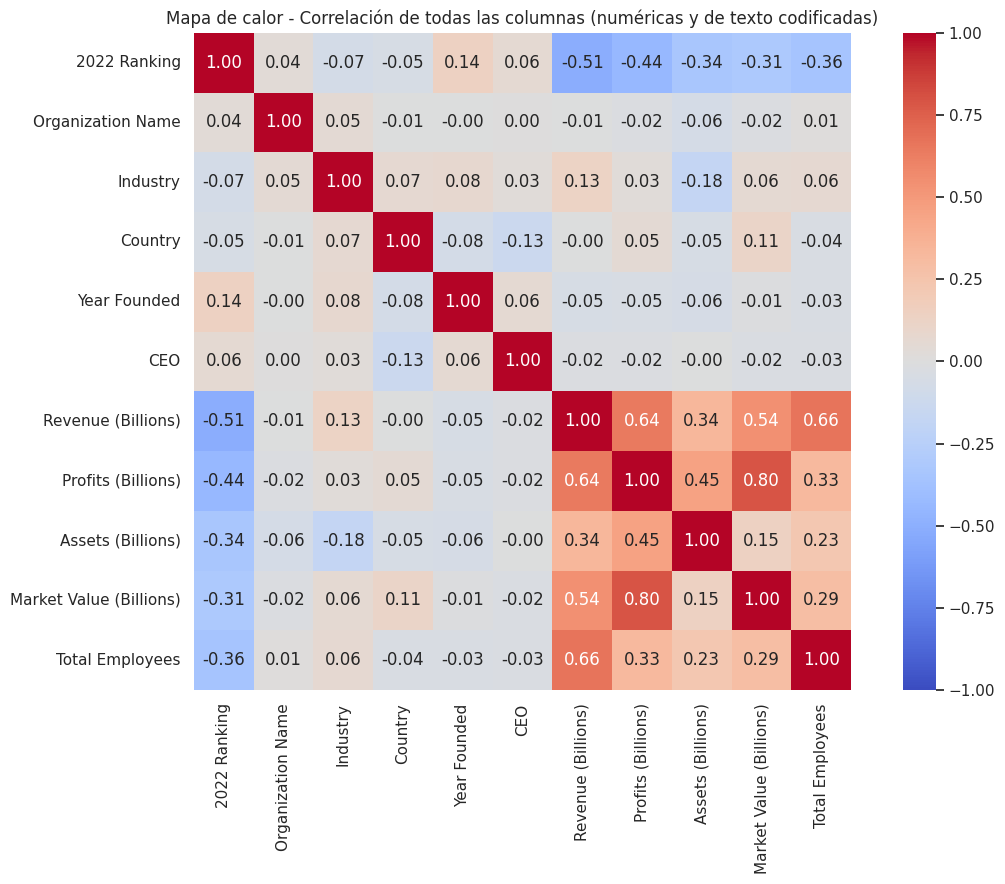

<font color="orange">**Justificación:** Las correlaciones más fuertes están entre las variables numéricas de tamaño: `Profits` con `Market Value` (≈ 0.80), `Revenue` con `Total Employees` (≈ 0.66) y `Revenue` con `Profits` (≈ 0.64). `2022 Ranking` tiene correlación negativa con `Revenue` (≈ -0.51), `Profits` (≈ -0.44) y `Total Employees` (≈ -0.36): tiene sentido porque el ranking 1 es la mejor posición, así que a mayor ingreso o ganancia, menor es el número de ranking. Las columnas de texto codificadas (`Organization Name`, `Industry`, `Country`, `CEO`) tienen correlaciones cercanas a 0 con todo (la más notable es `Industry` con `Assets`, ≈ -0.18). **Precaución:** el código numérico de una categoría depende solo del orden alfabético, no de una magnitud real, por lo que estas correlaciones no son muy significativas. `Organization Name` y `CEO` son prácticamente identificadores únicos (1,999 y 1,963 valores distintos), así que no aportan información útil sobre el resto de las variables.</font>

In [ ]:
# Primeros tres registros
forbes_df.head(3)

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
0,1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
1,2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
2,3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# ültimos 3 registros
forbes_df.tail(3)

,2022 Ranking,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
1996,1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944
1997,1997,Sichuan Changhong Electric,Consumer Durables,China,1988,Wei Li,15.72,0.05,12.10,1.96,51841
1998,1999,Satellite Chemical,Chemicals,China,0,No Data,4.41,0.93,7.64,9.52,3409


In [ ]:
# Cambiando el índice del dataframe. El inplace indica que el cambio se guaradará en el dataframe
forbes_df.set_index('2022 Ranking', inplace=True)
forbes_df

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621
...,...,...,...,...,...,...,...,...,...,...
1995,Aperam,Materials,Luxembourg,2010,Timoteo di Maulo,6.03,1.14,6.72,3.16,0
1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,1998,Shan Min Huang,0.04,1.41,0.17,1.14,306
1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944


In [ ]:
# Ya no se puede hacer referencia a la columna como forbes_df['Ranking 2022'] porque ya es índice del dataframe, ahora se debe usar forbes_df.index
forbes_df.index

Int64Index([   1,    2,    3,    4,    5,    6,    7,    8,    9,   10,
            ...
            1989, 1991, 1992, 1993, 1993, 1995, 1995, 1997, 1997, 1999],
           dtype='int64', name='2022 Ranking', length=1999)

In [ ]:
# Cantidad de valores únicos por columna
forbes_df.nunique()

Organization Name          1999
Industry                     29
Country                      57
Year Founded                214
CEO                        1963
Revenue (Billions)         1587
Profits (Billions)          688
Assets (Billions)          1790
Market Value (Billions)    1665
Total Employees            1726
dtype: int64

In [ ]:
# Valores únicos de una columna en particular
forbes_df['Industry'].unique()

array(['Diversified Financials', 'Banking', 'Oil & Gas Operations',
       'Retailing', 'Technology Hardware & Equipment',
       'Consumer Durables', 'IT Software & Services', 'Insurance',
       'Telecommunications Services', 'Media', 'Drugs & Biotechnology',
       'Food, Drink & Tobacco', 'Semiconductors',
       'Household & Personal Products', 'Materials', 'Conglomerates',
       'Trading Companies', 'Transportation', 'Construction',
       'Aerospace & Defense', 'Utilities',
       'Health Care Equipment & Services', 'Chemicals', 'Capital Goods',
       'Business Services & Supplies', 'Hotels, Restaurants & Leisure',
       'Food Markets', 'Food & Drink', 'Automotive'], dtype=object)

In [ ]:
# Frecuencia de valores únicos de una columna en particular
forbes_df['Industry'].value_counts()

Banking                             289
Diversified Financials              146
Construction                        127
Materials                           117
Oil & Gas Operations                106
Insurance                           105
Consumer Durables                    89
Utilities                            83
Business Services & Supplies         82
Chemicals                            75
IT Software & Services               73
Food, Drink & Tobacco                73
Transportation                       70
Retailing                            69
Drugs & Biotechnology                67
Capital Goods                        59
Technology Hardware & Equipment      56
Health Care Equipment & Services     44
Telecommunications Services          43
Trading Companies                    37
Semiconductors                       35
Household & Personal Products        33
Conglomerates                        29
Food Markets                         26
Media                                25


In [ ]:
# Con normalize=True se obtiene el porcentaje
forbes_df['Industry'].value_counts(normalize=True)

Banking                             0.144572
Diversified Financials              0.073037
Construction                        0.063532
Materials                           0.058529
Oil & Gas Operations                0.053027
Insurance                           0.052526
Consumer Durables                   0.044522
Utilities                           0.041521
Business Services & Supplies        0.041021
Chemicals                           0.037519
IT Software & Services              0.036518
Food, Drink & Tobacco               0.036518
Transportation                      0.035018
Retailing                           0.034517
Drugs & Biotechnology               0.033517
Capital Goods                       0.029515
Technology Hardware & Equipment     0.028014
Health Care Equipment & Services    0.022011
Telecommunications Services         0.021511
Trading Companies                   0.018509
Semiconductors                      0.017509
Household & Personal Products       0.016508
Conglomera

In [ ]:
# Podemos hacer slicing del resultado (primeros 5 registros)
forbes_df['Country'].value_counts()[:5]

United States     584
China             297
Japan             196
South Korea        65
United Kingdom     64
Name: Country, dtype: int64

In [ ]:
# Podemos hacer slicing del resultado (últimos 5 registros)
forbes_df['Country'].value_counts()[-5:]

Czech Republic    1
Bahrain           1
Uruguay           1
Peru              1
Nigeria           1
Name: Country, dtype: int64

In [ ]:
# Para ordenar por la columna especificada
forbes_df.sort_values('Year Founded', ascending=False)

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
613,Warner Bros. Discovery,Media,United States,2022,David M. Zaslav,12.18,1.02,34.43,49.92,11000
79,Stellantis,Consumer Durables,Netherlands,2021,Carlos Tavares,176.61,16.78,195.33,44.26,281595
1579,Royalty Pharma,Drugs & Biotechnology,United States,2020,Pablo Gerardo Legorreta,2.29,0.62,17.52,18.48,66
109,Raytheon Technologies,Aerospace & Defense,United States,2020,Gregory J. Hayes,64.36,3.86,161.40,149.76,174000
355,Paramount,Media,United States,2019,Bob Bakish,28.59,4.54,58.62,20.13,22965
...,...,...,...,...,...,...,...,...,...,...
1696,Shanghai Commercial & Savings Bank,Banking,Taiwan,0,Shan Chung Chen,1.72,0.51,77.33,7.59,12577
1699,Daishi Hokuetsu Financial Group,Banking,Japan,0,No Data,1.20,0.12,90.37,0.89,3774
1919,Shandong Iron and Steel,Materials,China,0,Ming Lv,17.14,0.19,11.38,2.72,21949


In [ ]:
# Como no se incluyó el parámetro inplace=True en el ordenamiento, los cambios NO se guardan
forbes_df

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
1,Berkshire Hathaway,Diversified Financials,United States,1939,Warren Edward Buffett,276.09,89.80,958.78,741.48,372000
2,ICBC,Banking,China,1984,Shu Gu,208.13,54.03,5518.51,214.42,449296
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493
4,JPMorgan Chase,Diversified Financials,United States,2000,Jamie Dimon,124.54,42.12,3954.69,374.45,271025
5,China Construction Bank,Banking,China,2014,Wang Zuji,202.07,46.89,4746.95,181.32,352621
...,...,...,...,...,...,...,...,...,...,...
1995,Aperam,Materials,Luxembourg,2010,Timoteo di Maulo,6.03,1.14,6.72,3.16,0
1995,Shenzhen Feima International Supply Chain,Business Services & Supplies,China,1998,Shan Min Huang,0.04,1.41,0.17,1.14,306
1997,NMDC,Materials,India,1958,Sumit Deb,3.52,1.41,5.72,6.40,16944


In [ ]:
# Valores faltantes del dataframe (celdas que no tienen info) Se representan en pandas como NaN (Not A Number)
# En este dataframe no hay celdas sin info en ninguna columna
forbes_df.isna().sum()

Organization Name          0
Industry                   0
Country                    0
Year Founded               0
CEO                        0
Revenue (Billions)         0
Profits (Billions)         0
Assets (Billions)          0
Market Value (Billions)    0
Total Employees            0
dtype: int64

In [ ]:
# Aplicando estadísticas descriptivas en una columna
forbes_df['Profits (Billions)'].max()

105.36

In [ ]:
# Filtrando información en el dataframe con una condición
forbes_df[forbes_df['Profits (Billions)'] == forbes_df['Profits (Billions)'].max()]

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
2022 Ranking,,,,,,,,,,
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# Otra forma de hacerlo
# La función idxmax() devuelve el índice del registro con el valor máximo de Profits (Billions) = 3
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()]

Organization Name          Saudi Arabian Oil Company (Saudi Aramco)
Industry                                       Oil & Gas Operations
Country                                                Saudi Arabia
Year Founded                                                   1933
CEO                                        Amin bin Hasan Al-Nasser
Revenue (Billions)                                           400.38
Profits (Billions)                                           105.36
Assets (Billions)                                            576.04
Market Value (Billions)                                     2292.08
Total Employees                                               68493
Name: 3, dtype: object

In [ ]:
# La serie anterior se puede convertir a un dataframe
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()].to_frame()

,3
Organization Name,Saudi Arabian Oil Company (Saudi Aramco)
Industry,Oil & Gas Operations
Country,Saudi Arabia
Year Founded,1933
CEO,Amin bin Hasan Al-Nasser
Revenue (Billions),400.38
Profits (Billions),105.36
Assets (Billions),576.04
Market Value (Billions),2292.08
Total Employees,68493


In [ ]:
# Con el atributo T se obtiene la transpuesta de la tabla anterior
forbes_df.loc[forbes_df['Profits (Billions)'].idxmax()].to_frame().T

,Organization Name,Industry,Country,Year Founded,CEO,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
3,Saudi Arabian Oil Company (Saudi Aramco),Oil & Gas Operations,Saudi Arabia,1933,Amin bin Hasan Al-Nasser,400.38,105.36,576.04,2292.08,68493


In [ ]:
# Las estadísticas descriptivas se pueden aplicar también a todo el dataframe y el cálculo se efectúa por columna
forbes_df.mean(numeric_only=True)

Year Founded                1863.992496
Revenue (Billions)            23.886628
Profits (Billions)             2.503167
Assets (Billions)            117.176013
Market Value (Billions)       38.260675
Total Employees            48871.218609
dtype: float64

In [ ]:
# El resultado indica que, en promedio, el valor de mercado se desvía de la media en 117 billones aproximadamente
forbes_df['Market Value (Billions)'].std()

117.23330138551884

In [ ]:
# El 75% de las empresas tienen ganancias iguales o menores a 2.27 billones
forbes_df['Profits (Billions)'].quantile(.75)

2.27

In [ ]:
# La función describe() regresa un resumen de varias estadísticas descriptivas para todas las columnas numéricas del dataframe
forbes_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year Founded,1999.0,1863.992496,421.815723,0.00,1919.000,1971.00,1996.00,2022.00
Revenue (Billions),1999.0,23.886628,40.951362,0.00,5.600,12.17,23.73,572.75
Profits (Billions),1999.0,2.503167,6.160483,-12.05,0.590,1.06,2.27,105.36
Assets (Billions),1999.0,117.176013,363.826515,0.17,14.800,32.10,77.88,5518.51
Market Value (Billions),1999.0,38.260675,117.233301,0.14,7.335,16.64,34.72,2640.32
Total Employees,1999.0,48871.218609,98603.185213,0.00,7154.500,20507.00,51442.50,2300000.00


In [ ]:
# También se puede obtener un resumen para las variables de texto
forbes_df.describe(include='object').T

,count,unique,top,freq
Organization Name,1999,1999,Berkshire Hathaway,1
Industry,1999,29,Banking,289
Country,1999,57,United States,584
CEO,1999,1963,No Data,23


In [ ]:
# Con groupby() se forman particiones o grupos, de manera que dentro de cada grupo todas las filas tengan el mismo valor en la columna especificada
# En esta caso, saca el promedio por industria para todas las columnas numéricas del dataframe
forbes_df.groupby('Industry').mean(numeric_only=True)

,Year Founded,Revenue (Billions),Profits (Billions),Assets (Billions),Market Value (Billions),Total Employees
Industry,,,,,,
Aerospace & Defense,1968.111111,27.293889,1.773333,49.955556,50.000556,70953.888889
Automotive,2013.500000,0.045000,-3.860000,15.085000,30.930000,7161.000000
Banking,1900.512111,14.133287,2.767785,390.609516,22.516228,33810.937716
Business Services & Supplies,1923.426829,12.461463,1.668659,121.980610,36.172927,41872.573171
Capital Goods,1744.474576,18.056780,1.325254,29.158814,27.682373,50124.711864
Chemicals,1821.840000,14.358000,1.646267,21.027333,21.925067,22615.280000
Conglomerates,1869.172414,23.352069,2.118276,51.668276,37.351379,76758.827586
Construction,1735.795276,22.788189,1.404331,58.032992,12.035197,44925.653543
Consumer Durables,1904.662921,38.928876,2.814157,60.011798,36.157753,84848.808989


In [ ]:
# Si estamos interesados en una columna en particular, se filtra el dataframe, antes de hacer el groupby()
forbes_df[['Assets (Billions)', 'Industry']].groupby('Industry').mean()

,Assets (Billions)
Industry,
Aerospace & Defense,49.955556
Automotive,15.085000
Banking,390.609516
Business Services & Supplies,121.980610
Capital Goods,29.158814
Chemicals,21.027333
Conglomerates,51.668276
Construction,58.032992
Consumer Durables,60.011798


In [ ]:
# Se pueden ordenar los valores resultantes del groupby()
forbes_df[['Assets (Billions)', 'Industry']].groupby('Industry').mean().sort_values('Assets (Billions)', ascending=False)

,Assets (Billions)
Industry,
Banking,390.609516
Insurance,224.384190
Diversified Financials,180.981986
Business Services & Supplies,121.980610
Telecommunications Services,90.579535
Oil & Gas Operations,73.279151
Trading Companies,71.822973
Utilities,63.647711
Consumer Durables,60.011798


In [ ]:
# Se pueden definir varios niveles de agrupamiento
forbes_df[['Assets (Billions)','Industry','Country']].groupby(['Industry','Country']).mean()

Assets (Billions)
Industry            Country                                
Aerospace & Defense Canada                       138.550000
                    China                         21.010000
                    France                        34.410000
                    Italy                         32.270000
                    Netherlands                  129.160000
...                                                     ...
Utilities           South Korea                  177.590000
                    Spain                         88.550000
                    United Arab Emirates          49.060000
                    United Kingdom                75.740000
                    United States                 62.473571

[495 rows x 1 columns]

<Axes: ylabel='Frequency'>

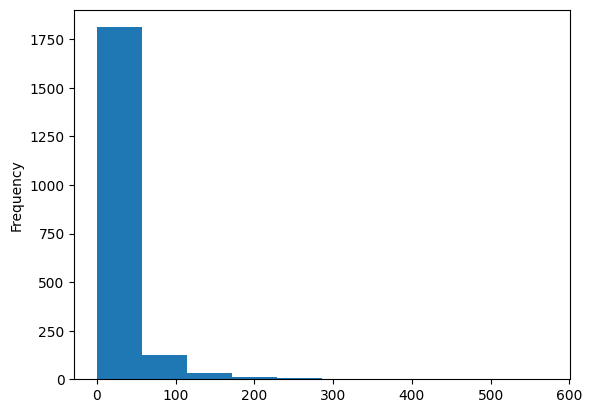

In [ ]:
# En el método plot() se especifica el tipo de gráfico a construir con el parámetro kind
# Cada columna representa una clase o bin (incluye un rango de valores)
forbes_df['Revenue (Billions)'].plot(kind='hist')

<Axes: ylabel='Frequency'>

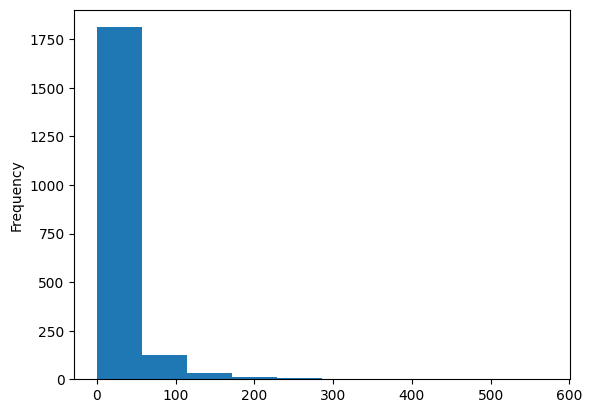

In [ ]:
# Lo anterior es equivalente a colocar el tipo de gráfico después del plot y separado por un punto
forbes_df['Revenue (Billions)'].plot.hist()

<Axes: ylabel='Frequency'>

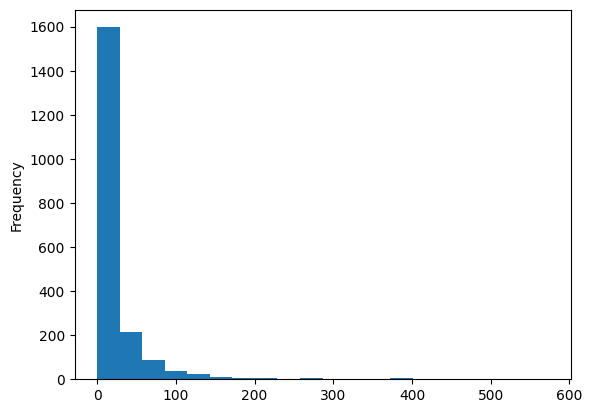

In [ ]:
# Por defecto se dibujan 10 bins, aunque en el gráfico anterior no se alcanzan a apreciar por el sesgo
# Pero este número se puede cambiar
forbes_df['Revenue (Billions)'].plot(kind='hist', bins=20)

<Axes: ylabel='Frequency'>

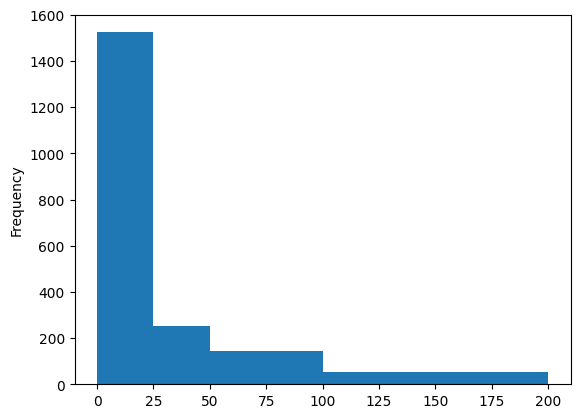

In [ ]:
# También se pueden enumerar los límites de todos los bins, sin necesidad de que sean equidistantes
forbes_df['Revenue (Billions)'].plot(kind='hist', bins=[0,25,50,100,200])

<Axes: ylabel='Frequency'>

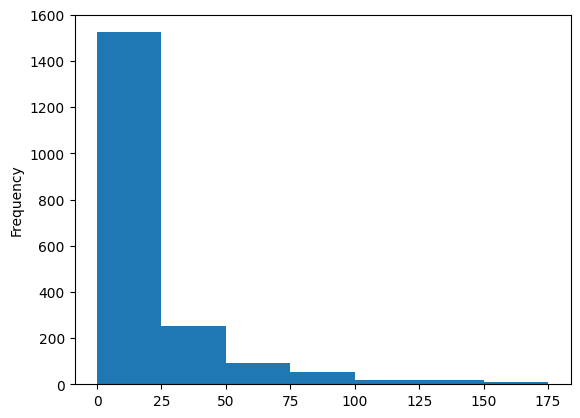

In [ ]:
# Si son equidistantes, se pueden indicar con el método arange(inicio, fin, incremento) de numpy
import numpy as np
forbes_df['Revenue (Billions)'].plot.hist(bins=np.arange(0,200,25))

array([[<Axes: title={'center': 'Year Founded'}>,
        <Axes: title={'center': 'Revenue (Billions)'}>],
       [<Axes: title={'center': 'Profits (Billions)'}>,
        <Axes: title={'center': 'Assets (Billions)'}>],
       [<Axes: title={'center': 'Market Value (Billions)'}>,
        <Axes: title={'center': 'Total Employees'}>]], dtype=object)

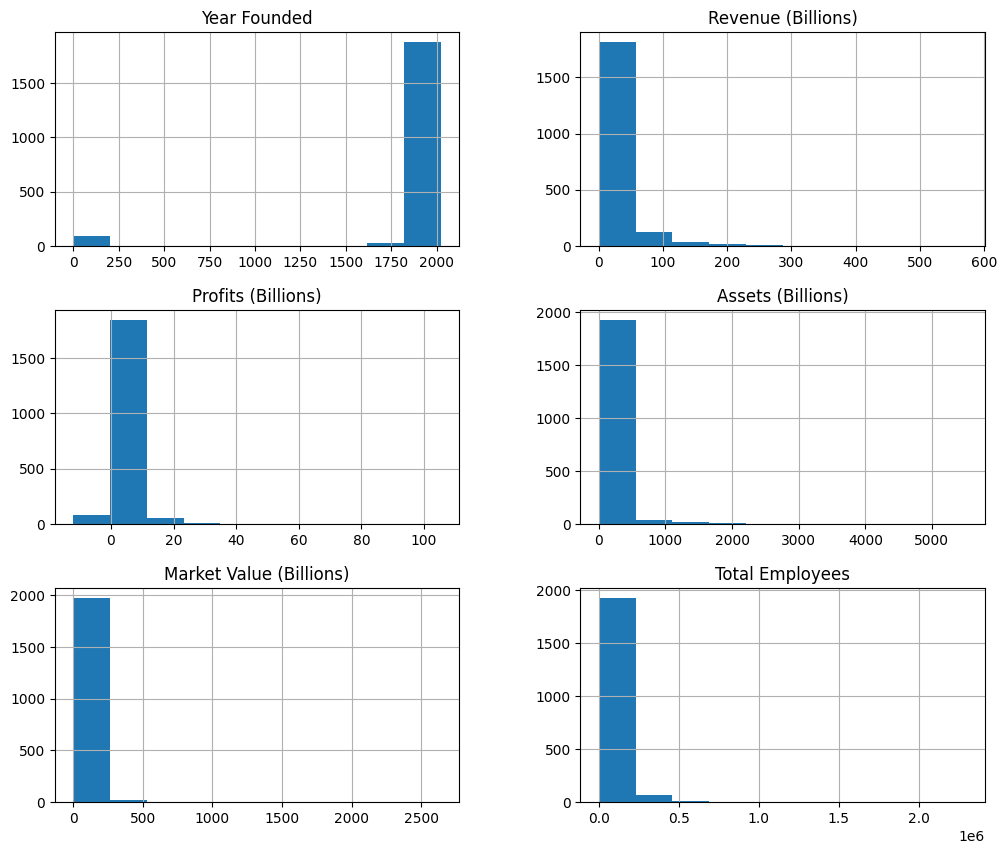

In [ ]:
# El método hist() del dataframe, obtiene un histograma para cada columna numérica
# Se puede ajustar el tamaño con figsize
forbes_df.hist(figsize=(12,10))